![Q1](blatt6q1.png)

### 1a) Basic assumptions for GDA and under which criterias are observations classified

GDA is a supervised ML algorithm which assumes that the observations of each class can be modelled using a Multivariate Normal Distribution, i.e, the class-conditional distribution $p(x \mid y = c, \theta)$ is a Multivariate Normal Distribution, while the class labels follow a categorical distribution with $p(y = c \mid \theta) = \pi_c$.

GDA uses Bayes rule and the previous assumption. So we have,

$$
p(y = c \mid x,\theta) = \frac{p(x \mid y = c, \theta) \cdot p(y = c \mid \theta)}{\sum_{c'} p(x \mid y = c', \theta)\cdot p(y = c' \mid \theta)}
$$

where, $p(x \mid y = c, \theta) = \mathcal{N}(x \mid \mu_c,\Sigma_c)$ according to the assumption and also let $p(y = c \mid \theta) = \pi_c$

then we have,

$$
p(y = c \mid x,\theta) = \frac{\mathcal{N}(x \mid \mu_c,\Sigma_c) \cdot \pi_c}{\sum_{c'} \mathcal{N}(x \mid \mu_{c'},\Sigma_{c'}) \cdot \pi_{c'}}
$$

### 1b) Assumptions and model parameters for the following models  
- QDA (Quadratic Discriminant Analysis)

  QDA is a special type of GDA where the covariance matrices for the $k$ classes, i.e, $\Sigma_c \in \mathbb{R}^{d \times d}$ where $c \in \mathbb{N}_k$ do not necessarily need to be equal just like the mean vectors $\mu_c \in \mathbb{R}^d$ therefore the model parameters are $\theta = \{ \mu_c, \Sigma_c, \pi_c \}$.
  
- LDA (Linear Discriminant Analysis)

  LDA is a special type of GDA where the covariance matrices for the $k$ classes, i.e, $\Sigma_c \in \mathbb{R}^{d \times d}$ where $c \in \mathbb{N}_k$ are strictly equal unlike the mean vectors $\mu_c \in \mathbb{R}^d$ therefore the model parameters are $\theta = \{ \mu_c, \Sigma, \pi_c \}$.

- Naive Bayes

  Naive Bayes methods are a set of supervised learning algorithms based on applying Bayes’ theorem with the “naive” assumption of conditional independence between every pair of features given the value of the class variable.

  Given a class $y = c$ and features $x_1,\dots,x_d$ we have Bayes' rule where,

  $p(y = c \mid x_1, \dots, x_d) = \dfrac{p(x_1, \dots, x_d \mid y = c)\cdot p(y = c)}{p(x_1, \dots, x_d)}$

  Since the features are conditionally independent given $y = c$, we have,

  $p(y = c \mid x_1, \dots, x_d) = \dfrac{p(y = c)\cdot \prod_{j = 1}^{d} p(x_j \mid y = c)}{p(x_1, \dots, x_d)}$

  Since the denominator doesn't vary, the posterior is directly proportional and dependent on the joint probability, $p(y = c)\cdot \prod_{j = 1}^{d} p(x_j \mid y = c)$

  So we have $\hat{y} = \underset{c}{\text{argmax}}\left[ p(y = c)\cdot \displaystyle\prod_{j = 1}^{d} p(x_j \mid y = c) \right]$

  In the Gaussian case, $x_j \mid y = c \sim \mathcal{N}(\mu_{c,j}, \sigma^2_{c,j})$, so the covariance matrices are diagonal, i.e, $\Sigma_c = \text{diag}(\sigma^2_{c,1}, \dots, \sigma^2_{c,d})$, therefore the model parameters are $\theta = \{ \pi_c, \mu_c, \sigma^2_{c,1}, \dots, \sigma^2_{c,d} \}_{c=1}^{K}$ with $\sigma^2_{c,j} > 0$, $\pi_c \geq 0$ and $\sum_c \pi_c = 1$.

### 1c) Diagrams

QDA and LDA

![QDA_LDA](qda_lda_3_classes.png)

Gaussian Naive Bayes

![Gaussian Naive Bayes](gnb.png)

### 1e) Show that QDA decision boundary has a specific form

Set $p(y = 1 \mid x,\theta) = p(y = 2 \mid x,\theta)$

$\iff\mathcal{N}(x \mid \mu_1,\Sigma_1) \cdot \pi_1 = \mathcal{N}(x \mid \mu_2,\Sigma_2) \cdot \pi_2$

$\iff \ln{(\mathcal{N}(x \mid \mu_1,\Sigma_1) \cdot \pi_1)} = \ln{(\mathcal{N}(x \mid \mu_2,\Sigma_2) \cdot \pi_2)}$

$\iff \ln{(\mathcal{N}(x \mid \mu_1,\Sigma_1))} + \ln{(\pi_1)} = \ln{(\mathcal{N}(x \mid \mu_2,\Sigma_2))} + \ln{(\pi_2)}$

$\iff \ln{\left(\dfrac{1}{\sqrt{(2 \pi)^d}}\right)} - \dfrac{1}{2}\ln{(|\Sigma_1|)} - \dfrac{1}{2} (x - \mu_1)^T\Sigma_1^{-1}(x - \mu_1) + \ln{(\pi_1)} = \ln{\left(\dfrac{1}{\sqrt{(2 \pi)^d}}\right)} - \dfrac{1}{2}\ln{(|\Sigma_2|)} - \dfrac{1}{2} (x - \mu_2)^T\Sigma_2^{-1}(x - \mu_2) + \ln{(\pi_2)}$

$\iff -\dfrac{1}{2}\ln{(|\Sigma_1|)} - \dfrac{1}{2} (x - \mu_1)^T\Sigma_1^{-1}(x - \mu_1) + \ln{(\pi_1)} = -\dfrac{1}{2}\ln{(|\Sigma_2|)} - \dfrac{1}{2} (x - \mu_2)^T\Sigma_2^{-1}(x - \mu_2) + \ln{(\pi_2)}$

$\iff -\dfrac{1}{2}\ln{(|\Sigma_1|)} - \dfrac{1}{2} (x^T\Sigma_1^{-1} - \mu_1^T\Sigma_1^{-1})(x - \mu_1) + \ln{(\pi_1)} = -\dfrac{1}{2}\ln{(|\Sigma_2|)} - \dfrac{1}{2} (x^T\Sigma_2^{-1} - \mu_2^T\Sigma_2^{-1})(x - \mu_2) + \ln{(\pi_2)}$

$\iff -\dfrac{1}{2}\ln{(|\Sigma_1|)} - \dfrac{1}{2} (x^T\Sigma_1^{-1}x - x^T\Sigma_1^{-1}\mu_1 - \mu_1^T\Sigma_1^{-1}x + \mu_1^T\Sigma_1^{-1}\mu_1) + \ln{(\pi_1)} = -\dfrac{1}{2}\ln{(|\Sigma_2|)} - \dfrac{1}{2} (x^T\Sigma_2^{-1}x - x^T\Sigma_2^{-1}\mu_2 - \mu_2^T\Sigma_2^{-1}x + \mu_2^T\Sigma_2^{-1}\mu_2) + \ln{(\pi_2)}$

Since $\Sigma_c^{-1}$ is symmetric, i.e, $\Sigma_c^{-T} = \Sigma_c^{-1}$ we have,

$\iff -\dfrac{1}{2}\ln{(|\Sigma_1|)} - \dfrac{1}{2} (x^T\Sigma_1^{-1}x - 2 \mu_1^T\Sigma_1^{-1}x + \mu_1^T\Sigma_1^{-1}\mu_1) + \ln{(\pi_1)} = -\dfrac{1}{2}\ln{(|\Sigma_2|)} - \dfrac{1}{2} (x^T\Sigma_2^{-1}x - 2 \mu_2^T\Sigma_2^{-1}x + \mu_2^T\Sigma_2^{-1}\mu_2) + \ln{(\pi_2)}$

$\iff \ln{(|\Sigma_1|)} + (x^T\Sigma_1^{-1}x - 2 \mu_1^T\Sigma_1^{-1}x + \mu_1^T\Sigma_1^{-1}\mu_1) - 2 \ln{(\pi_1)} = \ln{(|\Sigma_2|)} + (x^T\Sigma_2^{-1}x - 2 \mu_2^T\Sigma_2^{-1}x + \mu_2^T\Sigma_2^{-1}\mu_2) - 2 \ln{(\pi_2)}$

$\iff \ln{(|\Sigma_1|)} + (x^T\Sigma_1^{-1}x - 2 \mu_1^T\Sigma_1^{-1}x + \mu_1^T\Sigma_1^{-1}\mu_1) - 2 \ln{(\pi_1)} - [\ln{(|\Sigma_2|)} + (x^T\Sigma_2^{-1}x - 2 \mu_2^T\Sigma_2^{-1}x + \mu_2^T\Sigma_2^{-1}\mu_2) - 2 \ln{(\pi_2)}] = 0$

$\iff (x^T\Sigma_1^{-1}x - 2 \mu_1^T\Sigma_1^{-1}x + \mu_1^T\Sigma_1^{-1}\mu_1) - (x^T\Sigma_2^{-1}x - 2 \mu_2^T\Sigma_2^{-1}x + \mu_2^T\Sigma_2^{-1}\mu_2) + \ln{(|\Sigma_1|)} - \ln{(|\Sigma_2|)} + 2 \ln{(\pi_2)} - 2 \ln{(\pi_1)} = 0$

$\iff (x^T\Sigma_1^{-1}x - x^T\Sigma_2^{-1}x) + 2 (\mu_2^T\Sigma_2^{-1}x - \mu_1^T\Sigma_1^{-1}x) + (\mu_1^T\Sigma_1^{-1}\mu_1 - \mu_2^T\Sigma_2^{-1}\mu_2) + \ln{\left( \dfrac{|\Sigma_1|}{|\Sigma_2|} \right)} + 2 \ln{\left( \dfrac{\pi_2}{\pi_1} \right)} = 0$

$\iff x^T (\Sigma_1^{-1} - \Sigma_2^{-1}) x + 2 (\mu_2^T\Sigma_2^{-1} - \mu_1^T\Sigma_1^{-1}) x + (\mu_1^T\Sigma_1^{-1}\mu_1 - \mu_2^T\Sigma_2^{-1}\mu_2) + \ln{\left( \dfrac{|\Sigma_1|}{|\Sigma_2|} \right)} + 2 \ln{\left( \dfrac{\pi_2}{\pi_1} \right)} = 0$

Here,

$A = \Sigma_1^{-1} - \Sigma_2^{-1}$

$b = 2 (\Sigma_2^{-1}\mu_2 - \Sigma_1^{-1}\mu_1)$

$c = (\mu_1^T\Sigma_1^{-1}\mu_1 - \mu_2^T\Sigma_2^{-1}\mu_2) + \ln{\left( \dfrac{|\Sigma_1|}{|\Sigma_2|} \right)} + 2 \ln{\left( \dfrac{\pi_2}{\pi_1} \right)}$

### 1d) Show that LDA classification has specific form of inequations for two classes

Since LDA is a specific form of QDA with the additional condition being shared covariance matrices, we have,

$A = \Sigma^{-1} - \Sigma^{-1} = 0$

$m = 2 (\Sigma^{-1}\mu_2 - \Sigma^{-1}\mu_1) = 2 \Sigma^{-1}(\mu_2 - \mu_1)$

$b = (\mu_1^T\Sigma^{-1}\mu_1 - \mu_2^T\Sigma^{-1}\mu_2) + \ln{\left( \dfrac{|\Sigma|}{|\Sigma|} \right)} + 2 \ln{\left( \dfrac{\pi_2}{\pi_1} \right)} = (\mu_1 - \mu_2)^T\Sigma^{-1}(\mu_1 + \mu_2) + 2 \ln{\left( \dfrac{\pi_2}{\pi_1} \right)}$

So now $m^T x + b = 0$, i.e, the decision boundary becomes,

$2 (\Sigma^{-1}(\mu_2 - \mu_1))^T x + (\mu_1 - \mu_2)^T\Sigma^{-1}(\mu_1 + \mu_2) + 2 \ln{\left( \dfrac{\pi_2}{\pi_1} \right)} = 0$

Since $m^T x + b = 0$ is the decision boundary, any $x$ with $m^T x + b < 0$ and with any $x$ with $m^T x + b > 0$ are considered of classes $1,2$ respectively so we have the form,

$m^T x < -b$ and $m^T x > -b$

So setting $w = m, c = -b$ we have the form of $w^T x < c$ and $w^T x > c$

As for why $m^T x + b < 0$ and $m^T x + b > 0$ with any $x$ are considered of classes $1,2$ respectively, its because we originally set $p(y = 1 \mid x,\theta) - p(y = 2 \mid x,\theta) = 0$ for the decision boundary from which, we had,

$\ln{(\mathcal{N}(x \mid \mu_1,\Sigma_1) \cdot \pi_1)} - \ln{(\mathcal{N}(x \mid \mu_2,\Sigma_2) \cdot \pi_2)} = 0$

$\iff -2\cdot (\ln{(\mathcal{N}(x \mid \mu_1,\Sigma_1) \cdot \pi_1)} - \ln{(\mathcal{N}(x \mid \mu_2,\Sigma_2) \cdot \pi_2)}) = 0$

$\iff  2\cdot (\ln{(\mathcal{N}(x \mid \mu_2,\Sigma_2) \cdot \pi_2)} - \ln{(\mathcal{N}(x \mid \mu_1,\Sigma_1) \cdot \pi_1)}) = 0$

which was used for the derivation of $m^T x + b = 0$ after assuming that the covariance matrices are the same for LDA case.

So the classes are then decided based on whether, $2\cdot (\ln{(\mathcal{N}(x \mid \mu_2,\Sigma_2) \cdot \pi_2)} - \ln{(\mathcal{N}(x \mid \mu_1,\Sigma_1) \cdot \pi_1)}) < 0$ and $2\cdot (\ln{(\mathcal{N}(x \mid \mu_2,\Sigma_2) \cdot \pi_2)} - \ln{(\mathcal{N}(x \mid \mu_1,\Sigma_1) \cdot \pi_1)}) > 0$ respectively.

So for $2\cdot (\ln{(\mathcal{N}(x \mid \mu_2,\Sigma_2) \cdot \pi_2)} - \ln{(\mathcal{N}(x \mid \mu_1,\Sigma_1) \cdot \pi_1)}) < 0$, we have, $\ln{(\mathcal{N}(x \mid \mu_2,\Sigma_2) \cdot \pi_2)} < \ln{(\mathcal{N}(x \mid \mu_1,\Sigma_1) \cdot \pi_1)}$, i.e, class $1$ has greater joint probability.

Similarly for $2\cdot (\ln{(\mathcal{N}(x \mid \mu_2,\Sigma_2) \cdot \pi_2)} - \ln{(\mathcal{N}(x \mid \mu_1,\Sigma_1) \cdot \pi_1)}) > 0$, we have, $\ln{(\mathcal{N}(x \mid \mu_2,\Sigma_2) \cdot \pi_2)} > \ln{(\mathcal{N}(x \mid \mu_1,\Sigma_1) \cdot \pi_1)}$, i.e, class $2$ has greater joint probability.

Since the denominators are equal for both classes when baye's rule is applied, the posterior is directly proportional to the joint probabilities of the classes respectively.

This concludes the justification of classifying to the respective classes based on the inequation.


![Q1](blatt6q2.png)

### 2a) The general formula for $p(y_i = c \mid x_i,\theta)$ for a QDA model and $\theta$ which specifies all possible model parameters is:

$$
p(y_i = c \mid x_i,\theta) = \frac{\mathcal{N}(x_i \mid \mu_c,\Sigma_c) \cdot \pi_c}{\sum_{c'} \mathcal{N}(x_i \mid \mu_{c'},\Sigma_{c'}) \cdot \pi_{c'}}
$$

where $\theta = \mu_c, \Sigma_c, \pi_c$

### 2b) Use MLE for the data

![image.png](qda_mle.png)

$\pi_1 = \pi_2 = \dfrac{4}{8} = \dfrac{1}{2}$

$\mu_1 = \dfrac{1}{4} \cdot \begin{pmatrix} 0 \\ 0 \end{pmatrix} = 0$

$\mu_2 = \dfrac{1}{4} \cdot \begin{pmatrix} 8 \\ 8 \end{pmatrix} = 2 \cdot \begin{pmatrix} 1 \\ 1 \end{pmatrix}$

$\Sigma_1 = \begin{pmatrix} 4 & -1 \\ -1 & 4 \end{pmatrix}$

$\Sigma_2 = \begin{pmatrix} 4 & 1 \\ 1 & 4 \end{pmatrix}$

###  2c) See Python Script below

### 2d) Use (1e) and set values of A,b,c accordingly

$A = \Sigma_1^{-1} - \Sigma_2^{-1} = \dfrac{1}{15} \cdot \begin{pmatrix} 0 & 2 \\ 2 & 0 \end{pmatrix}$

$b = 2 (\Sigma_2^{-1}\mu_2 - \Sigma_1^{-1}\mu_1) = \dfrac{4}{5} \cdot \begin{pmatrix} 1 \\ 1 \end{pmatrix}$

$c = (\mu_1^T\Sigma_1^{-1}\mu_1 - \mu_2^T\Sigma_2^{-1}\mu_2) + \ln{\left( \dfrac{|\Sigma_1|}{|\Sigma_2|} \right)} + 2 \ln{\left( \dfrac{\pi_2}{\pi_1} \right)} = \dfrac{-24}{15} + 0 + 0$

So now $x^T A x + b^T x + c = 0$ becomes,

$\dfrac{1}{15} \begin{pmatrix} x_1 \\ x_2 \end{pmatrix}^T \begin{pmatrix} 0 & 2 \\ 2 & 0 \end{pmatrix} \begin{pmatrix} x_1 \\ x_2 \end{pmatrix} + \dfrac{12}{15} \begin{pmatrix} 1 \\ 1 \end{pmatrix}^T \begin{pmatrix} x_1 \\ x_2 \end{pmatrix} - \dfrac{24}{15} = 0$

$\iff \begin{pmatrix} x_1 \\ x_2 \end{pmatrix}^T \begin{pmatrix} 0 & 2 \\ 2 & 0 \end{pmatrix} \begin{pmatrix} x_1 \\ x_2 \end{pmatrix} + 12 \begin{pmatrix} 1 \\ 1 \end{pmatrix}^T \begin{pmatrix} x_1 \\ x_2 \end{pmatrix} - 24 = 0$

$\iff \begin{pmatrix} 2x_2 \\ 2x_1 \end{pmatrix}^T \begin{pmatrix} x_1 \\ x_2 \end{pmatrix} + 12 (x_1 + x_2) - 24 = 0$

$\iff 2x_2 x_1 + 2x_1 x_2 + 12 (x_1 + x_2) - 24 = 0$

$\iff 4x_1 x_2 + 12 (x_1 + x_2) - 24 = 0$

$\iff x_1 x_2 + 3 (x_1 + x_2) - 6 = 0$

$\iff 3 x_1 - 6 = -3x_2 - x_1 x_2$

$\iff 3 x_1 - 6 = -x_2 (3 + x_1)$

$\iff \dfrac{6 - 3 x_1}{3 + x_1} = x_2$

no point lies on the boundary $x_1 = -3$.

### 2e) Shape of the decision boundary

The decision boundary $(x_1 + 3)(x_2 + 3) = 15$ is a hyperbola with center $(-3, -3)$ and asymptotes $x_1 = -3$ and $x_2 = -3$. Since $(x_1 + 3)$ and $(x_2 + 3)$ must have the same sign, its two branches lie to the upper right and lower left of the center. Only the upper right branch separates the two classes: it passes through $(0, 2)$ and $(2, 0)$ and crosses the line through the class means at $(\sqrt{15} - 3,\ \sqrt{15} - 3) \approx (0.87, 0.87)$, slightly closer to $\hat{\mu}_1$ than the midpoint $(1, 1)$. The lower left branch lies far away from the data. Since $|\hat{\Sigma}_1| = |\hat{\Sigma}_2|$ and $\hat{\pi}_1 = \hat{\pi}_2$, the boundary consists exactly of the points with equal Mahalanobis distance to both class means, i.e. it passes through the intersections of equally labelled level sets of the two classes. QDA assigns $x$ according to: $(x_1 + 3)(x_2 + 3) > 15 \Rightarrow$ class 2, $(x_1 + 3)(x_2 + 3) < 15 \Rightarrow$ class 1.

Note: the training points $(\sqrt{3}, \sqrt{3})$ (class 1) and $(2 - \sqrt{5},\ 2 - \sqrt{5})$ (class 2) lie on the wrong side of the boundary and are therefore misclassified by the fitted QDA model.

### f) Repeat (b) - (e) for LDA model

#### (fb) MLE LDA

$\Sigma = \begin{pmatrix} 4 & 0 \\ 0 & 4 \end{pmatrix}$ is the only term which is different from QDA

#### (fc) See Python Script below

#### (fd) Decision boundary

So, $\Sigma^{-1} = \dfrac{1}{4}\cdot\textbf{I}$

$A = \Sigma^{-1} - \Sigma^{-1} = 0$

$b = 2 (\Sigma^{-1}\mu_2 - \Sigma^{-1}\mu_1) = 2 \Sigma^{-1}(\mu_2 - \mu_1) = 2 \cdot \dfrac{1}{4}\cdot\textbf{I} \cdot 2 \cdot \begin{pmatrix} 1 \\ 1 \end{pmatrix} = \begin{pmatrix} 1 \\ 1 \end{pmatrix}$

$c = (\mu_1 - \mu_2)^T\Sigma^{-1}(\mu_1 + \mu_2) + 2 \ln{\left( \dfrac{\pi_2}{\pi_1} \right)} = -2 \cdot \begin{pmatrix} 1 \\ 1 \end{pmatrix}^T \cdot \dfrac{1}{4}\cdot\textbf{I}\cdot 2 \cdot \begin{pmatrix} 1 \\ 1 \end{pmatrix} = -\begin{pmatrix} 1 \\ 1 \end{pmatrix}^T \textbf{I} \begin{pmatrix} 1 \\ 1 \end{pmatrix} = -2$

So now $b^T x + c = 0$ becomes,

$\begin{pmatrix} 1 \\ 1 \end{pmatrix}^T \begin{pmatrix} x_1 \\ x_2 \end{pmatrix} - 2 = 0$

$\iff x_1 + x_2 - 2 = 0$

$\iff x_2 = 2 - x_1$

#### (fe) Shape of the decision boundary

The decision boundary is a straight line with slope $-1$ that passes through the midpoint $\frac{1}{2}(\hat{\mu}_1 + \hat{\mu}_2) = \begin{pmatrix} 1 \\ 1 \end{pmatrix}$ and is perpendicular to $\hat{\mu}_2 - \hat{\mu}_1 = 2\begin{pmatrix} 1 \\ 1 \end{pmatrix}$. It is therefore the perpendicular bisector of the segment between the two class means. Every point on it is equally far from $\hat{\mu}_1$ and $\hat{\mu}_2$, so (since $\hat{\Sigma} \propto \textbf{I}$ and $\hat{\pi}_1 = \hat{\pi}_2$) LDA assigns $x$ to the class with the closer mean: $x_1 + x_2 > 2 \Rightarrow$ class 2, $x_1 + x_2 < 2 \Rightarrow$ class 1.

Compared to QDA: the LDA line and the QDA hyperbola intersect at $(0, 2)$ and $(2, 0)$.

In [56]:
import numpy as np

mu_1 = np.array([0, 0])
mu_2 = np.array([2, 2])
xs = np.array([np.sqrt([3, 3]), 
               -np.sqrt([3, 3]), 
               [np.sqrt(5), -np.sqrt(5)], 
               [-np.sqrt(5), np.sqrt(5)], 
               [2 + np.sqrt(5), 2 + np.sqrt(5)],
               [2 - np.sqrt(5), 2 - np.sqrt(5)],
               [2 + np.sqrt(3), 2 - np.sqrt(3)],
               [2 - np.sqrt(3), 2 + np.sqrt(3)],               
              ])
ys = np.array([1,1,1,1,2,2,2,2])

N_1 = 0
N_2 = 0
sigma_1 = 0
sigma_2 = 0

for (i, c) in enumerate(ys):
    if c == 1:
        N_1 += 1
        sigma_1 += (xs[i] - mu_1)[:, None] @ (xs[i] - mu_1)[None]
    elif c == 2:
        N_2 += 1
        sigma_2 += (xs[i] - mu_2)[:, None] @ (xs[i] - mu_2)[None]

sigma = (sigma_1 + sigma_2).astype(np.int64) / (N_1 + N_2)
sigma_1 /= N_1
sigma_2 /= N_2

print("(b)")
print(f"Sigma_1:\n {sigma_1}\n")
print(f"Sigma_2:\n {sigma_2}\n")

print("(f)")
print(f"Sigma:\n {sigma}\n")

(b)
Sigma_1:
 [[ 4. -1.]
 [-1.  4.]]

Sigma_2:
 [[4. 1.]
 [1. 4.]]

(f)
Sigma:
 [[4. 0.]
 [0. 4.]]



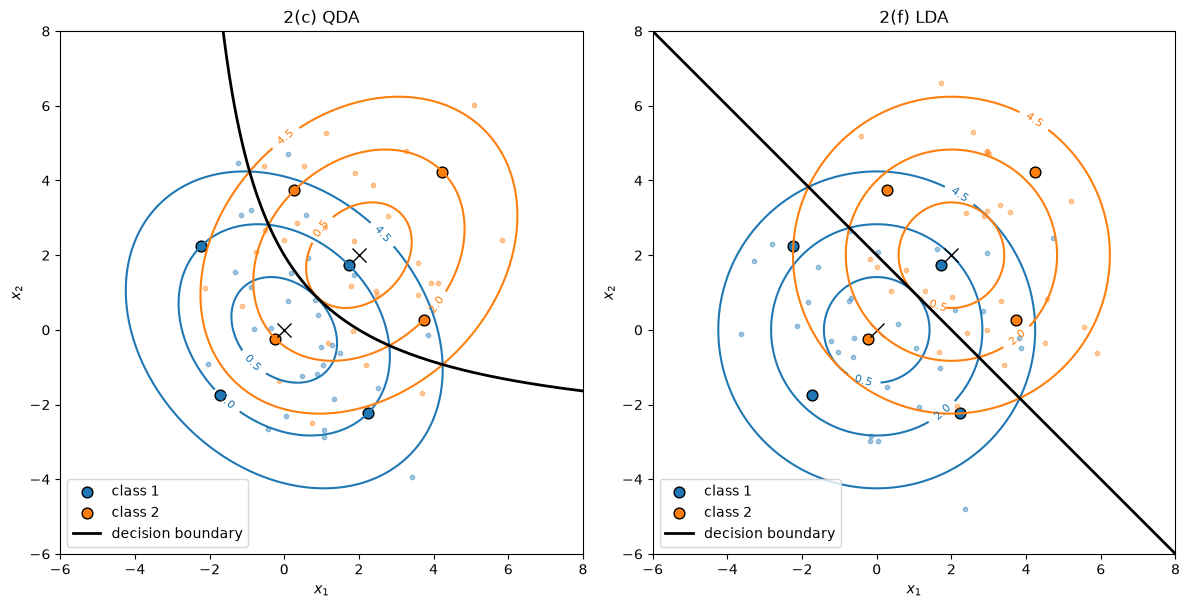

In [1]:
import numpy as np
import matplotlib.pyplot as plt

s3, s5 = np.sqrt(3), np.sqrt(5)
X = np.array([[s3, s3], [-s3, -s3], [s5, -s5], [-s5, s5],
              [2 + s5, 2 + s5], [2 - s5, 2 - s5], [2 + s3, 2 - s3], [2 - s3, 2 + s3]])
y = np.array([1, 1, 1, 1, 2, 2, 2, 2])

# ML estimates
mu = {c: X[y == c].mean(axis=0) for c in (1, 2)}
Sig = {c: np.cov(X[y == c].T, bias=True) for c in (1, 2)}        # QDA: per class
Sig_lda = sum((y == c).sum() * Sig[c] for c in (1, 2)) / len(y)  # LDA: pooled

g = np.linspace(-6, 8, 400)
G1, G2 = np.meshgrid(g, g)
P = np.stack([G1, G2], axis=-1)
x1 = np.linspace(-6, 8, 400)
rng = np.random.default_rng(0)

def panel(ax, covs, title, boundary):
    for c, col in ((1, "tab:blue"), (2, "tab:orange")):
        d = P - mu[c]
        M = np.einsum("...i,ij,...j->...", d, np.linalg.inv(covs[c]), d)  # Mahalanobis^2
        cs = ax.contour(G1, G2, M, levels=[0.5, 2, 4.5], colors=col)
        ax.clabel(cs, fontsize=8)
        S = rng.multivariate_normal(mu[c], covs[c], 30)
        ax.scatter(*S.T, s=10, color=col, alpha=0.4)
        ax.scatter(*X[y == c].T, s=60, color=col, edgecolor="k", label=f"class {c}")
        ax.plot(*mu[c], "kx", ms=10)
    ax.plot(x1, boundary(x1), "k", lw=2, label="decision boundary")
    ax.set(xlim=(-6, 8), ylim=(-6, 8), aspect="equal", title=title, xlabel="$x_1$", ylabel="$x_2$")
    ax.legend(loc="lower left")

fig, (a, b) = plt.subplots(1, 2, figsize=(12, 6))

# QDA boundary: x2 = (6 - 3 x1) / (3 + x1); hide the jump at x1 = -3
qda = lambda t: np.where(np.abs(t + 3) < 0.05, np.nan, (6 - 3 * t) / (3 + t))
panel(a, Sig, "2(c) QDA", qda)
panel(b, {1: Sig_lda, 2: Sig_lda}, "2(f) LDA", lambda t: 2 - t)

plt.tight_layout()
plt.show()